# Exploring hospital vital signs (NEWS) – from Orange to Python

**INF-3770 · Health data analysis – hands-on session**

In the lecture you saw how vital-sign registrations from Nordland Hospital Trust were clustered with advanced
time-series models. Here you'll take simpler steps with the same kind of data:

| Part | Question | Main technique |
|---|---|---|
| 1 | What do the measurements look like? Are there errors? | Histograms, box plots, summary statistics |
| 2 | Which vital signs move together, and which drive the NEWS score? | Correlation, scatter plots |
| 3 | Can a machine *learn* the NEWS rules from data? | Decision tree (supervised learning) |
| 4 | Can we find groups of similar patients without labels? | Feature aggregation, PCA, k-means, silhouette (unsupervised learning) |

**How to use this notebook.** Each part starts with a box called **🟠 In Orange** describing a workflow you can
build in [Orange Data Mining](https://orangedatamining.com/) by connecting widgets. Do that first, then run the
**🐍 In Python** cells to see the same steps in code with `pandas` (tables), `matplotlib`/`seaborn` (plots) and
`scikit-learn` (machine learning). You don't need to know these libraries beforehand. Read the comments, run the
cells top to bottom (Shift + Enter), and change things to see what happens.

Cells marked **✏️ Try it** are small exercises.

## The data

Each row is **one registration of vital signs** for a patient at a given time. A patient usually has several rows.

| Column | Meaning |
|---|---|
| `PatientID` | Anonymous patient identifier |
| `WardID`, `WardName` | Hospital ward (in Norwegian, e.g. *Medisinsk enhet* = medical unit, *Kirurgisk post* = surgical ward, *Intensiv* = ICU) |
| `Timestamp` | Time of registration, in milliseconds since 1 Jan 1970 (Unix time) |
| `Systolic`, `Diastolic` | Blood pressure (mmHg) |
| `O2` | Oxygen saturation, SpO₂ (%) |
| `Pulse` | Heart rate (beats/min) |
| `Temp` | Body temperature (°C) |
| `Rf` | Respiration rate (breaths/min) |
| `Consciousness` | `Våken` = alert; the other values mean reduced consciousness |
| `AirOrO2` | `Luft` = breathing room air, `Oksygen` = receiving extra oxygen |
| `EwsScore` | The **NEWS2** early-warning score, 0–20. 5 or more triggers an urgent clinical response |
| `EwsType` | Which SpO₂ scale was used: 1 = standard, 2 = for patients with chronic lung disease (hypercapnia) |
| `Gender` | Patient gender (may be missing) |

### NEWS2 scoring table (for reference)

Each vital sign gives 0–3 points, and the NEWS score is the sum. Score 0 means "normal".

| Vital sign | 3 | 2 | 1 | **0** | 1 | 2 | 3 |
|---|---|---|---|---|---|---|---|
| Respiration rate | ≤ 8 | | 9–11 | **12–20** | | 21–24 | ≥ 25 |
| SpO₂ (scale 1) | ≤ 91 | 92–93 | 94–95 | **≥ 96** | | | |
| Extra oxygen | | yes | | **no (air)** | | | |
| Systolic BP | ≤ 90 | 91–100 | 101–110 | **111–219** | | | ≥ 220 |
| Pulse | ≤ 40 | | 41–50 | **51–90** | 91–110 | 111–130 | ≥ 131 |
| Consciousness | | | | **alert** | | | not alert = 3 |
| Temperature | ≤ 35.0 | | 35.1–36.0 | **36.1–38.0** | 38.1–39.0 | ≥ 39.1 | |

Diastolic pressure is **not** part of NEWS.

## Part 0 · Loading the data

### 🟠 In Orange
1. Drag a **File** widget onto the canvas and open the CSV file.
2. In the File widget's table of columns, set the **role** of each column:
   * `Index`, `WardID`, `Timestamp`, `Gender` → **skip** (`Gender` may be empty)
   * `PatientID` → change its *type* to **categorical** and its role to **meta** (we'll need it in Part 4)
   * `WardName` → **meta**
   * everything else → **feature**

   Press **Apply**.
3. Connect a **Data Table** widget to see the rows, and a **Feature Statistics** widget for a quick overview
   (min, max, mean and missing values per column).

### 🐍 In Python

In [ ]:
# Libraries: pandas = tables, numpy = numbers, matplotlib/seaborn = plots, sklearn = machine learning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Colours used throughout (a colour-blind-safe palette)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
PALETTE = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e2dc", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.dpi": 110, "font.size": 10,
})

DATA_PATH = "extract.csv"          # <- change this if your file has another name or location
df = pd.read_csv(DATA_PATH)

print("Rows, columns:", df.shape)
df.head()                          # show the first 5 rows

The raw file needs a little cleaning before we use it:
* turn the Norwegian text columns into simple yes/no columns,
* turn `Timestamp` into a real date,
* group the many wards into a few **ward types**,
* drop `Gender` if it is completely empty.

In [ ]:
# A column of True/False: is the patient on extra oxygen? Is the patient alert?
df["on_oxygen"] = df["AirOrO2"] == "Oksygen"
df["alert"] = df["Consciousness"] == "Våken"

# Unix milliseconds -> readable date and time
df["time"] = pd.to_datetime(df["Timestamp"], unit="ms")

# Group the wards by keywords in their (Norwegian) names
def ward_type(name):
    name = name.lower()
    if "intensiv" in name or "overvåkning" in name or "akutt" in name or "observasjon" in name:
        return "Acute / intensive"
    if "kir" in name or "ortoped" in name:
        return "Surgical"
    if "med" in name:
        return "Medical"
    return "Other"

df["ward_type"] = df["WardName"].apply(ward_type)

if df["Gender"].isna().all():
    df = df.drop(columns="Gender")
    print("Gender is empty in this file, so it was dropped.")

# The six vital signs we will work with
VITALS = ["Systolic", "Diastolic", "O2", "Pulse", "Temp", "Rf"]

print("Time span:", df["time"].min(), "to", df["time"].max())
print("Number of patients:", df["PatientID"].nunique())
print(df["ward_type"].value_counts())

---
## Part 1 · What do the measurements look like?

Always look at your data before doing any machine learning. The vital signs here were **typed in by hand** by
nurses, so we should expect some errors.

### 🟠 In Orange
1. **Feature Statistics**: look at min, max and mean of each vital sign. Is anything physically impossible?
2. **Distributions** widget (connect it to File): pick each vital sign in turn. Change the bin width.
   Try **Split by** `AirOrO2`.
3. **Box Plot** widget: choose `O2` as the variable and **Subgroups** `AirOrO2`. Then try `Rf`.
4. In the **Data Table**, click a column header to sort it and look at the most extreme rows.

### 🐍 In Python
`describe()` gives the same overview as Feature Statistics:

In [3]:
df[VITALS + ["EwsScore"]].describe().round(1)

,Systolic,Diastolic,O2,Pulse,Temp,Rf,EwsScore
count,999.0,999.0,999.0,999.0,999.0,999.0,999.0
mean,130.2,71.9,95.3,79.9,36.6,18.2,1.9
std,23.3,14.3,3.3,16.0,0.6,3.4,2.1
min,67.0,30.0,63.0,27.0,34.7,10.0,0.0
25%,114.0,62.0,94.0,68.0,36.1,16.0,0.0
50%,129.0,71.0,96.0,79.0,36.5,18.0,1.0
75%,144.0,80.0,97.0,89.0,37.0,20.0,3.0
max,233.0,123.0,100.0,135.0,39.6,38.0,12.0


Now a histogram for each vital sign. The **grey band** shows the NEWS2 "normal" range (0 points).
Bars outside the band are what add points to a patient's NEWS score.

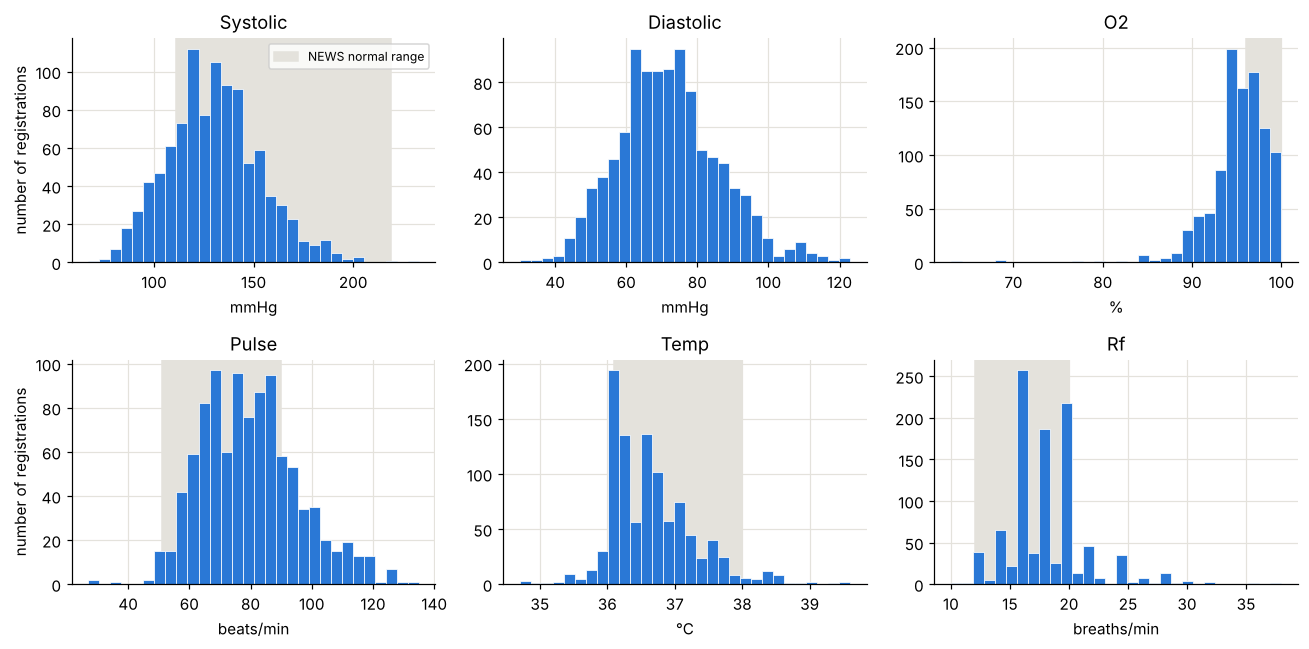

In [4]:
# NEWS2 normal ranges (0 points). Diastolic is not part of NEWS, so it has no band.
NORMAL = {"Systolic": (111, 219), "O2": (96, 100), "Pulse": (51, 90),
          "Temp": (36.1, 38.0), "Rf": (12, 20)}
UNITS = {"Systolic": "mmHg", "Diastolic": "mmHg", "O2": "%", "Pulse": "beats/min",
         "Temp": "°C", "Rf": "breaths/min"}

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, VITALS):
    if col in NORMAL:
        ax.axvspan(*NORMAL[col], color="#e4e2dc", zorder=0, label="NEWS normal range")
    ax.hist(df[col], bins=30, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(col)
    ax.set_xlabel(UNITS[col])
axes[0, 0].legend(loc="upper right", fontsize=8)
axes[0, 0].set_ylabel("number of registrations")
axes[1, 0].set_ylabel("number of registrations")
plt.tight_layout()
plt.show()

**Questions to discuss**
* Which vital signs are symmetric ("bell-shaped") and which are skewed?
* SpO₂ cannot be above 100 %. Is the shape of the `O2` histogram surprising?
* `Temp` and `Rf` look "spiky". Why? (Hint: how do nurses round numbers when they write them down?)

Now let's look for suspicious values, the same as sorting columns in Orange's Data Table:

In [5]:
# The 5 lowest and 5 highest values of each vital sign
for col in VITALS:
    values = df[col].sort_values()
    print(f"{col:10s} lowest: {list(values.head(5))}   highest: {list(values.tail(5))}")

Systolic   lowest: [67.0, 75.0, 76.0, 80.0, 81.0]   highest: [200.0, 201.0, 203.0, 220.0, 233.0]
Diastolic  lowest: [30.0, 34.0, 37.0, 39.0, 41.0]   highest: [115.0, 116.0, 117.0, 122.0, 123.0]
O2         lowest: [63.0, 68.0, 69.0, 77.0, 80.0]   highest: [100.0, 100.0, 100.0, 100.0, 100.0]
Pulse      lowest: [27.0, 28.0, 37.0, 46.0, 46.0]   highest: [127.0, 127.0, 127.0, 129.0, 135.0]
Temp       lowest: [34.7, 34.7, 34.7, 35.0, 35.1]   highest: [39.0, 39.0, 39.4, 39.5, 39.6]
Rf         lowest: [10.0, 11.0, 11.0, 12.0, 12.0]   highest: [32.0, 32.0, 32.0, 36.0, 38.0]


In [6]:
# Show the full rows for some extreme registrations. Are they errors or very sick patients?
df[(df["O2"] < 80) | (df["Pulse"] < 40) | (df["Temp"] < 35) | (df["Systolic"] > 220)][
    ["PatientID", "ward_type"] + VITALS + ["on_oxygen", "EwsScore"]]

,PatientID,ward_type,Systolic,Diastolic,O2,Pulse,Temp,Rf,on_oxygen,EwsScore
37,2605217,Medical,126.0,78.0,68.0,108.0,36.7,30.0,False,7
120,2660707,Medical,115.0,72.0,94.0,82.0,34.7,28.0,True,9
223,2676252,Surgical,156.0,85.0,98.0,37.0,36.1,14.0,False,3
296,2673942,Medical,150.0,62.0,94.0,80.0,34.7,22.0,False,6
345,2674604,Medical,112.0,60.0,69.0,108.0,36.9,20.0,False,4
347,2677899,Surgical,233.0,122.0,97.0,117.0,37.3,20.0,False,5
439,2677823,Medical,151.0,83.0,98.0,28.0,36.1,20.0,False,3
605,2677823,Medical,131.0,73.0,96.0,27.0,36.1,16.0,False,3
756,2678688,Medical,122.0,68.0,95.0,61.0,34.7,19.0,False,4
794,2659624,Medical,113.0,41.0,77.0,87.0,36.1,20.0,False,3


A box plot shows the median (middle line), the middle 50 % of the data (the box) and outliers (dots).
Here we compare oxygen saturation and respiration rate for patients **on room air vs. extra oxygen**:

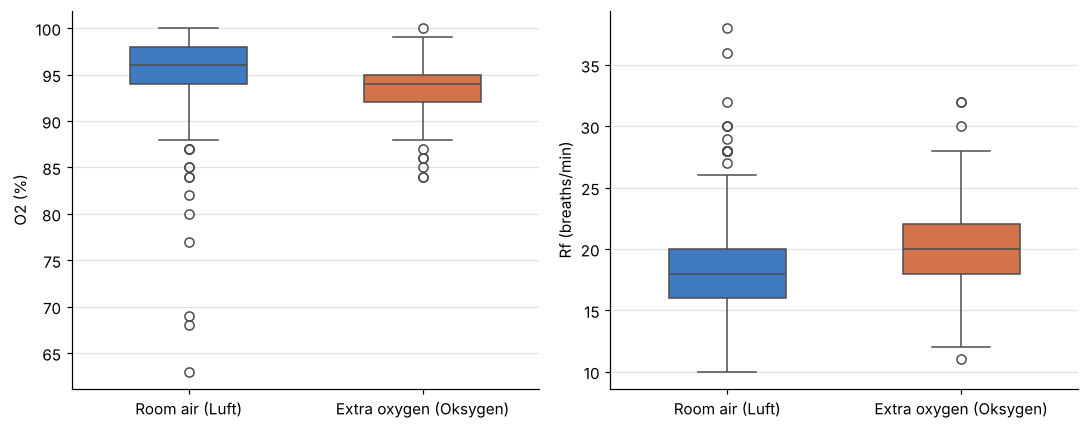

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["O2", "Rf"]):
    sns.boxplot(data=df, x="AirOrO2", y=col, hue="AirOrO2", palette=[BLUE, ORANGE],
                ax=ax, width=0.5, linewidth=1, legend=False)
    ax.set_xlabel("")
    ax.set_xticks([0, 1], ["Room air (Luft)", "Extra oxygen (Oksygen)"])
    ax.set_ylabel(f"{col} ({UNITS[col]})")
plt.tight_layout()
plt.show()

**✏️ Try it**
1. Change `["O2", "Rf"]` above to other vital signs, and `x="AirOrO2"` to `x="ward_type"`. Which vitals differ most
   between ward types?
2. Patients on extra oxygen have *lower* SpO₂ than patients on room air, even though they get help to breathe.
   Why might that be?
3. If you found values that must be typing errors, how would you handle them before doing machine learning?
   Remove the row? Replace the value? Leave it?

---
## Part 2 · Which vital signs move together?

**Correlation** (Pearson's *r*) is a number between −1 and +1 that measures how well two variables follow a
**straight line** together:
* +1: when one goes up, the other goes up
* −1: when one goes up, the other goes down
* 0: no *linear* relationship (but there may still be a curved one!)

### 🟠 In Orange
1. **Correlations** widget (connect it to File): it lists all pairs of features ranked by correlation.
   Which pair is most strongly correlated? Which features correlate most with `EwsScore`?
2. **Scatter Plot** widget: put `Systolic` on the x-axis and `Diastolic` on the y-axis.
   Set **Color** to `EwsScore`. Turn on **Jittering** so points with the same value don't hide each other.
3. In the Scatter Plot, click **Find Informative Projections** to let Orange search for the most interesting pairs.

### 🐍 In Python

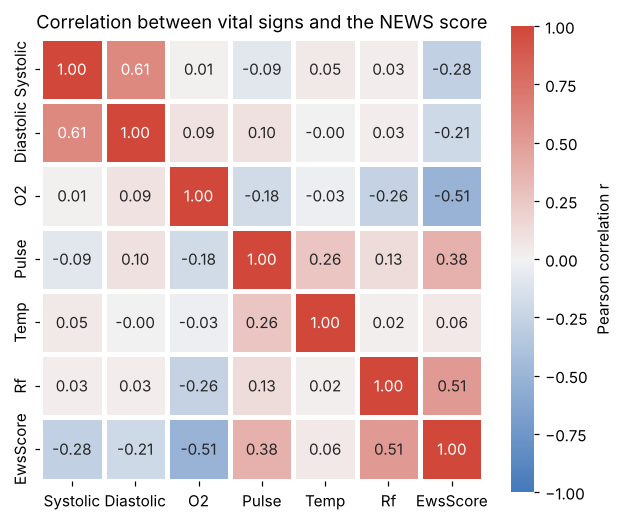

In [8]:
corr = df[VITALS + ["EwsScore"]].corr().round(2)

plt.figure(figsize=(6.5, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, square=True, linewidths=2,
            cmap=sns.diverging_palette(250, 15, s=75, l=50, center="light", as_cmap=True),
            cbar_kws={"label": "Pearson correlation r"})
plt.title("Correlation between vital signs and the NEWS score")
plt.show()

Read the bottom row: which vital signs correlate most with `EwsScore`, positively or negatively?

A **pair plot** shows a scatter plot for every pair of variables. Each point is one registration, coloured by
whether NEWS is **5 or more** (the threshold for an urgent response):

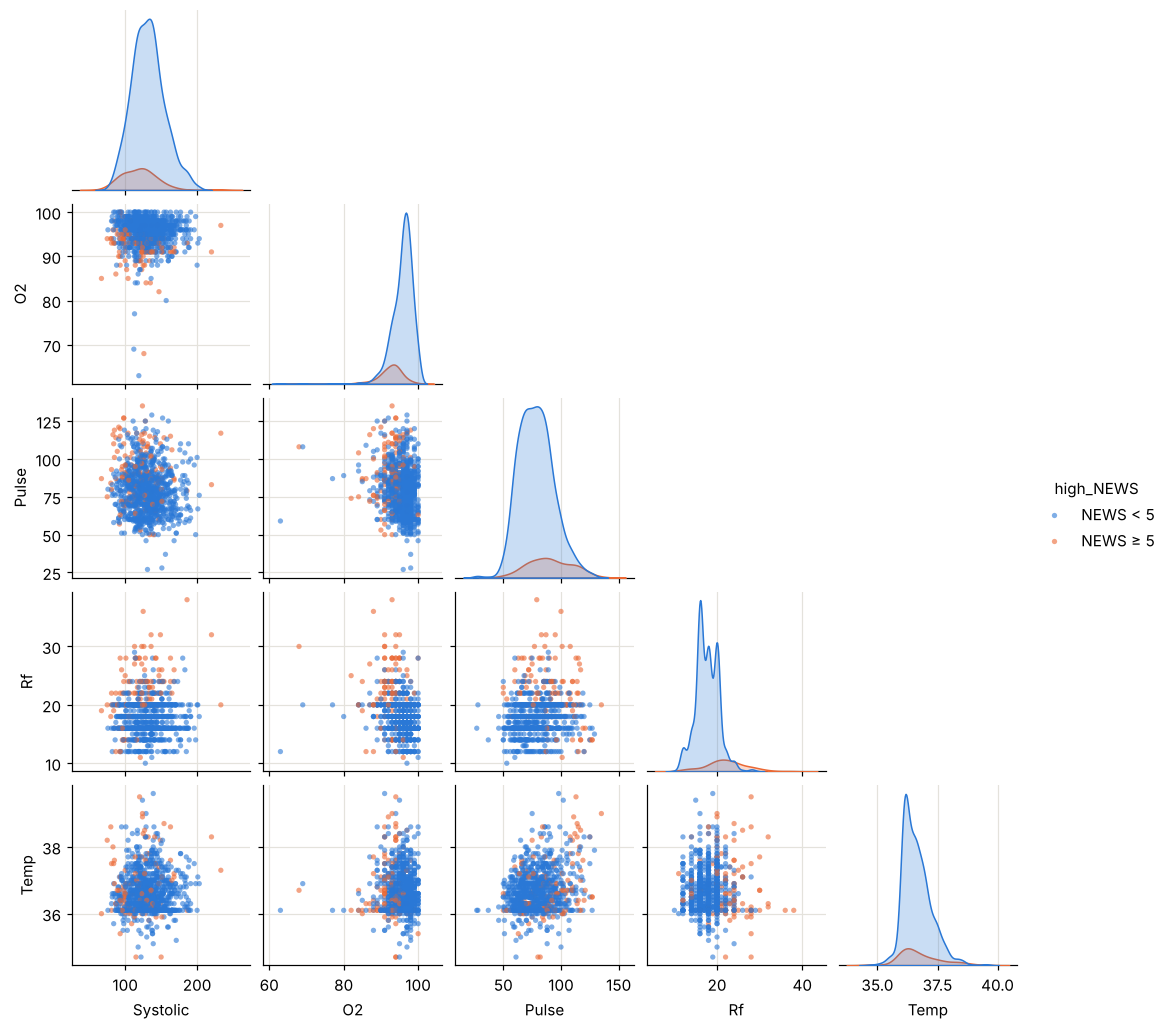

In [9]:
df["high_NEWS"] = np.where(df["EwsScore"] >= 5, "NEWS ≥ 5", "NEWS < 5")

sample = df.sample(min(len(df), 1500), random_state=0)   # at most 1500 points, so the plot stays readable
sns.pairplot(sample, vars=["Systolic", "O2", "Pulse", "Rf", "Temp"], hue="high_NEWS",
             hue_order=["NEWS < 5", "NEWS ≥ 5"], palette=[BLUE, ORANGE],
             plot_kws={"s": 12, "alpha": 0.6, "linewidth": 0}, height=1.9, corner=True)
plt.show()

### A trap: correlation only sees straight lines

`Temp` hardly correlates with `EwsScore`, yet it is part of the score. Look at the NEWS table: you get points
both when the temperature is **too low** and when it is **too high**. That is a U-shape, and a straight line
cannot describe a U-shape. The same rule applies to `Pulse`, but there most abnormal values are on the
*high* side, so a straight line already works fairly well. Compare the two plots:

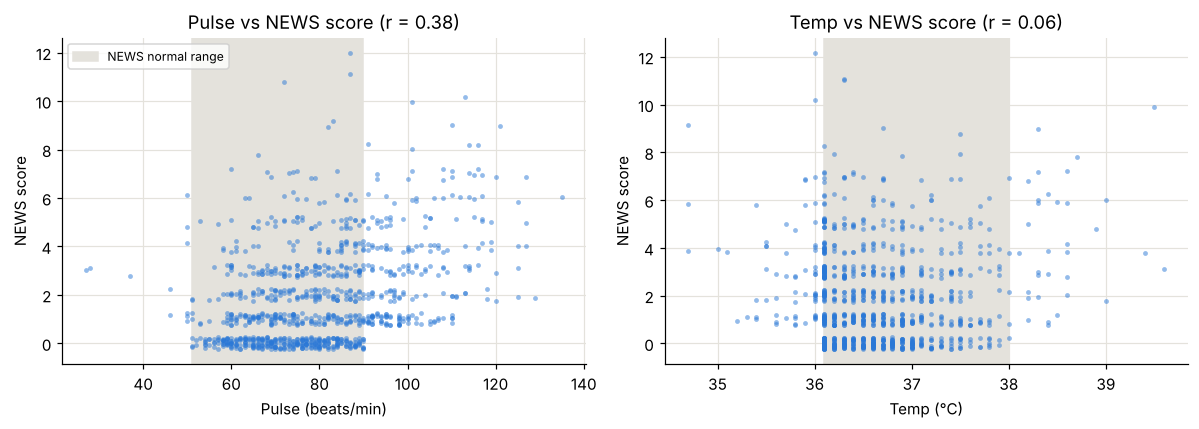

Pulse: r with raw value = 0.38, r with distance outside normal range = 0.37
Temp: r with raw value = 0.06, r with distance outside normal range = 0.24


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rng = np.random.default_rng(0)
for ax, col in zip(axes, ["Pulse", "Temp"]):
    jitter = rng.uniform(-0.25, 0.25, len(df))          # small random shift so points don't overlap
    ax.axvspan(*NORMAL[col], color="#e4e2dc", zorder=0, label="NEWS normal range")
    ax.scatter(df[col], df["EwsScore"] + jitter, s=10, alpha=0.5, color=BLUE, linewidth=0)
    r = df[col].corr(df["EwsScore"])
    ax.set_title(f"{col} vs NEWS score (r = {r:.2f})")
    ax.set_xlabel(f"{col} ({UNITS[col]})")
    ax.set_ylabel("NEWS score")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

# A new feature: how far outside the normal range is the value? (0 if inside)
# Does it give a stronger straight-line relationship than the raw value?
for col in ["Pulse", "Temp"]:
    low, high = NORMAL[col]
    distance = (low - df[col]).clip(lower=0) + (df[col] - high).clip(lower=0)
    print(f"{col}: r with raw value = {df[col].corr(df['EwsScore']):.2f}, "
          f"r with distance outside normal range = {distance.corr(df['EwsScore']):.2f}")

**✏️ Try it**
1. Systolic and diastolic blood pressure are strongly correlated. If you build a model, do you need both? What
   could go wrong if you include many features that say almost the same thing?
2. Make the "distance outside normal range" feature for `Rf` and `Systolic` too. Does the correlation with
   `EwsScore` go up?
3. *Correlation is not causation*: patients on extra oxygen have **higher** NEWS scores. Does the oxygen make
   them sicker?

---
## Part 3 · Can a machine learn the NEWS rules?

NEWS is a model made by **people**: experts chose the thresholds in the table above. Now we ask whether a
machine-learning model can **discover similar rules by itself**, just by looking at examples.

This is **supervised learning**: for every registration we know the right answer (the *label*). Our label is
"is NEWS 5 or more?" (yes/no), and the model must learn to predict it from the vital signs (the *features*).

We use a **decision tree**: a series of yes/no questions such as *"Is Rf > 20.5?"*. It's easy to read, so we can
compare its questions with the official table.

> ⚠️ **Data leakage.** `EwsScore` must **not** be a feature. The label is computed from it, so the model would
> just copy it and look perfect while learning nothing useful.

### 🟠 In Orange
1. **Feature Constructor** (called **Formula** in newer versions), connected to File:
   add a *categorical* variable `high_risk` with expression `1 if EwsScore >= 5 else 0` and values `no, yes`.
2. **Select Columns**: put `high_risk` as **Target**, the vital signs plus `AirOrO2`, `Consciousness` and
   `EwsType` as **Features**, and move `EwsScore` to **Ignored**.
3. Connect a **Tree** widget (set *Limit the maximal tree depth* to **3**), then a **Tree Viewer** to see the rules.
4. **Test and Score**: connect the data, the **Tree**, and a **Constant** learner (always predicts the most
   common class: our *baseline*). Use **cross-validation**. Compare CA (accuracy) and Recall.
5. Connect a **Confusion Matrix** to Test and Score. How many high-risk registrations does the tree miss?

### 🐍 In Python

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, ConfusionMatrixDisplay

# Features (X) and label (y). True/False columns become 1/0.
FEATURES = VITALS + ["on_oxygen", "alert", "EwsType"]
X = df[FEATURES].astype(float)
y = (df["EwsScore"] >= 5).astype(int)          # 1 = high risk, 0 = not

print(f"{y.mean():.1%} of registrations have NEWS ≥ 5")

# Hold back 30 % of the data for testing. The model never sees it during training.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print("Training rows:", len(X_train), "  Test rows:", len(X_test))

12.6% of registrations have NEWS ≥ 5


Training rows: 699   Test rows: 300


First a **baseline**: a "model" that always says *not high risk*. Any real model must beat this.

In [12]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = baseline.predict(X_test)
print(f"Baseline accuracy: {accuracy_score(y_test, pred):.1%}")
print(f"Baseline recall  : {recall_score(y_test, pred):.1%}  (share of high-risk cases it catches)")

Baseline accuracy: 87.3%
Baseline recall  : 0.0%  (share of high-risk cases it catches)


High accuracy, yet it catches **none** of the high-risk patients. When one class is rare, accuracy alone is
misleading. In a hospital, **recall** (how many sick patients we catch) matters a lot.

Now the decision tree:

Tree accuracy: 90.3%
Tree recall  : 55.3%


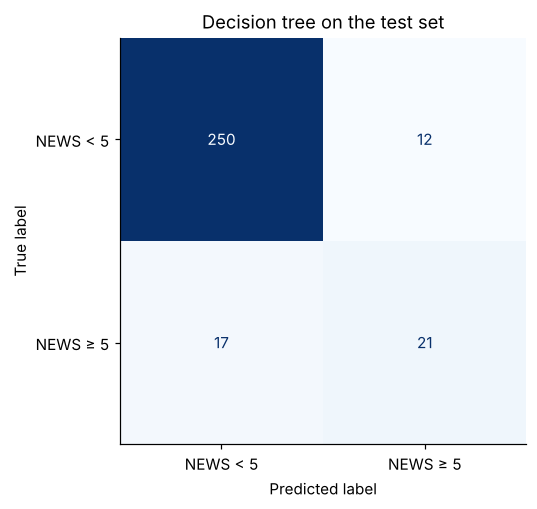

In [13]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)                     # "learning" happens here

pred = tree.predict(X_test)
print(f"Tree accuracy: {accuracy_score(y_test, pred):.1%}")
print(f"Tree recall  : {recall_score(y_test, pred):.1%}")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["NEWS < 5", "NEWS ≥ 5"], cmap="Blues", colorbar=False)
plt.title("Decision tree on the test set")
plt.grid(False)
plt.show()

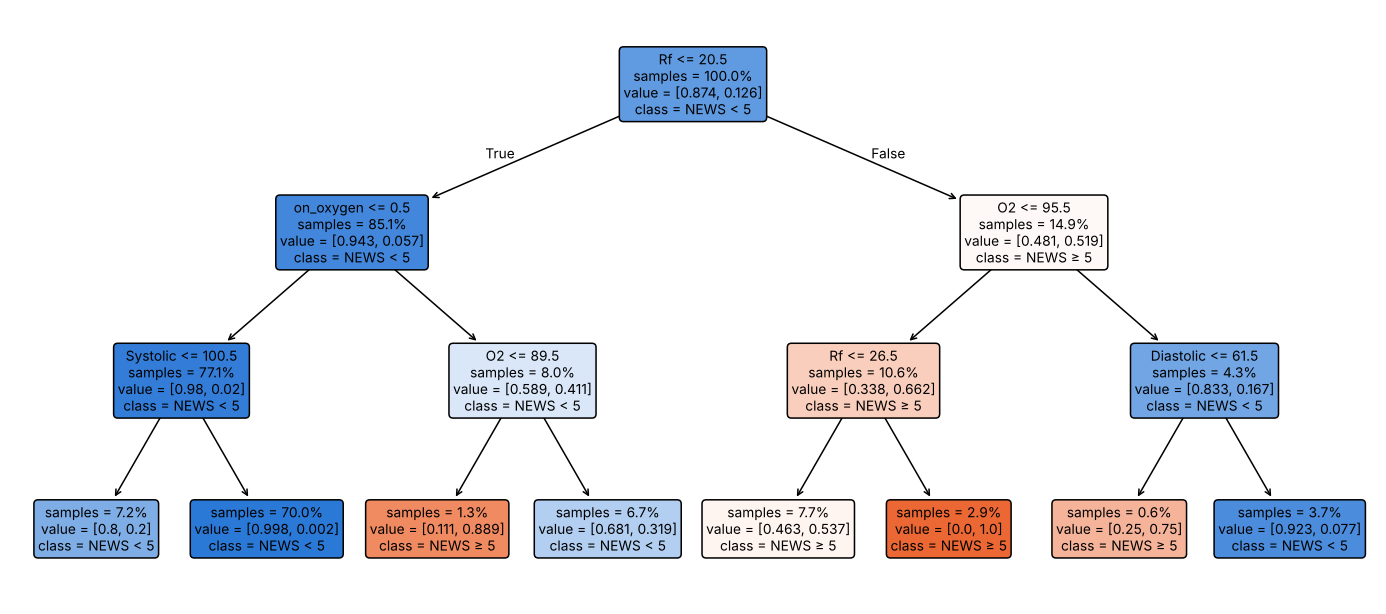

|--- Rf <= 20.5
|   |--- on_oxygen <= 0.5
|   |   |--- Systolic <= 100.5
|   |   |   |--- class: 0
|   |   |--- Systolic >  100.5
|   |   |   |--- class: 0
|   |--- on_oxygen >  0.5
|   |   |--- O2 <= 89.5
|   |   |   |--- class: 1
|   |   |--- O2 >  89.5
|   |   |   |--- class: 0
|--- Rf >  20.5
|   |--- O2 <= 95.5
|   |   |--- Rf <= 26.5
|   |   |   |--- class: 1
|   |   |--- Rf >  26.5
|   |   |   |--- class: 1
|   |--- O2 >  95.5
|   |   |--- Diastolic <= 61.5
|   |   |   |--- class: 1
|   |   |--- Diastolic >  61.5
|   |   |   |--- class: 0



In [14]:
import re
from matplotlib.colors import to_rgb

plt.figure(figsize=(16, 7))
boxes = plot_tree(tree, feature_names=FEATURES, class_names=["NEWS < 5", "NEWS ≥ 5"],
                  filled=True, rounded=True, impurity=False, proportion=True, fontsize=9)
# Recolour the boxes to match the rest of the notebook: blue = NEWS < 5, orange = NEWS ≥ 5,
# paler = less certain. (Only cosmetic; you can delete this loop.)
for box in boxes:
    found = re.search(r"value = \[[\d.]+, ([\d.]+)\]", box.get_text())
    if found is None:          # the "True"/"False" arrow labels are not boxes
        continue
    share_high = float(found.group(1))
    colour, strength = (ORANGE, 2 * share_high - 1) if share_high >= 0.5 else (BLUE, 1 - 2 * share_high)
    mix = [1 - strength * (1 - c) for c in to_rgb(colour)]
    box.get_bbox_patch().set_facecolor(mix)
plt.show()

# "value = [a, b]" in each box: the share of registrations with NEWS < 5 and NEWS ≥ 5 that reach that box

print(export_text(tree, feature_names=FEATURES, decimals=1))   # the same rules as text

**Compare with the NEWS2 table.** Look at the thresholds the tree chose, e.g. for `Rf`, `O2` and `on_oxygen`.
Are they close to the official cut-offs (Rf 20/24, SpO₂ 95/93/91, ...)? The tree never saw the table; it found
these values from the data alone.

### Overfitting: deeper is not always better
A deeper tree can ask more questions, so it fits the **training** data better. But does it get better on **new**
data?

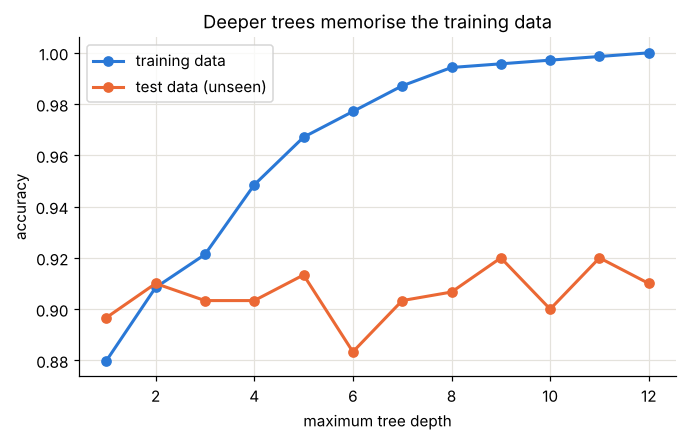

In [15]:
depths = range(1, 13)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(accuracy_score(y_train, m.predict(X_train)))
    test_acc.append(accuracy_score(y_test, m.predict(X_test)))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, marker="o", lw=2, color=BLUE, label="training data")
plt.plot(depths, test_acc, marker="o", lw=2, color=ORANGE, label="test data (unseen)")
plt.xlabel("maximum tree depth")
plt.ylabel("accuracy")
plt.title("Deeper trees memorise the training data")
plt.legend()
plt.show()

**✏️ Try it**
1. Add `"EwsScore"` to `FEATURES` and re-run. What happens to accuracy, and what does the tree look like? This is
   data leakage.
2. Remove `on_oxygen` from `FEATURES`. Which vital sign does the tree use instead?
3. Change the label to `df["EwsScore"] >= 7` (the "emergency" threshold). Is it harder to learn? Why?
4. Change `test_size` and `random_state` in `train_test_split`. Do the results change? What does that say about
   trusting one single test result?

---
## Part 4 · Finding groups of similar patients (clustering)

In the lecture, the goal was to find patient **"phenotypes"**: groups of patients with similar vital-sign
patterns. That is **unsupervised learning**: there is no label, and the algorithm must find structure by itself.

We repeat the lecture's simple **baseline** (slide 18):
1. **Remove time.** For each patient, compute **min, max and mean** of each of the 6 vital signs →
   6 × 3 = **18 numbers per patient**.
2. **Standardise** the features so that blood pressure (≈ 130) doesn't dominate temperature (≈ 37).
3. **PCA**: squeeze the 18 dimensions into 2, so we can plot them.
4. **k-means**: split patients into *k* clusters, and use the **silhouette score** to choose *k*.
5. **Interpret**: what do the clusters mean? Do they just repeat something we already knew?

### 🟠 In Orange
1. **Group By** (connected to File): group by `PatientID`. For each of the six vital signs, tick **Mean**, **Min**
   and **Max**. For `WardName` and `AirOrO2` tick **Mode** (most common value).
   (`PatientID` must be *categorical*; see Part 0.)
2. **Select Columns**: keep only the 18 vital-sign aggregates as **Features**; put the rest under **Metas**.
3. **Preprocess** → *Normalize features* → *Standardize to μ=0, σ²=1*.
4. **k-Means**: choose *From 2 to 6* clusters. The widget shows the **silhouette score** for each *k*;
   the highest is best.
5. **PCA** (connected to k-Means' output) with 2 components → **Scatter Plot** of PC1 vs PC2,
   **Color** = `Cluster`. Then change Color to `WardName - Mode` or `AirOrO2 - Mode`.
6. **Silhouette Plot**: shows how well each patient fits its cluster.
7. Optional: replace PCA with **t-SNE**, as in the lecture.

### 🐍 In Python

In [16]:
# Step 1: one row per patient. groupby + agg does the same as Orange's Group By widget.
patients = df.groupby("PatientID").agg(
    **{f"{v}_{f}": (v, f) for v in VITALS for f in ["min", "max", "mean"]},
    n_measurements=("EwsScore", "size"),
    max_NEWS=("EwsScore", "max"),
    share_on_oxygen=("on_oxygen", "mean"),
    ward_type=("ward_type", lambda s: s.mode()[0]),
)

MIN_MEASUREMENTS = 1      # ✏️ try 3: patients with one registration have min = max = mean
patients = patients[patients["n_measurements"] >= MIN_MEASUREMENTS]

FEATURE_COLS = [f"{v}_{f}" for v in VITALS for f in ["min", "max", "mean"]]
print("Patients:", len(patients), "  Features per patient:", len(FEATURE_COLS))
patients[FEATURE_COLS].head().round(1)

Patients: 306   Features per patient: 18


,Systolic_min,Systolic_max,Systolic_mean,Diastolic_min,Diastolic_max,Diastolic_mean,O2_min,O2_max,O2_mean,Pulse_min,Pulse_max,Pulse_mean,Temp_min,Temp_max,Temp_mean,Rf_min,Rf_max,Rf_mean
PatientID,,,,,,,,,,,,,,,,,,
528504,106.0,106.0,106.0,68.0,68.0,68.0,98.0,98.0,98.0,81.0,81.0,81.0,36.6,36.6,36.6,16.0,16.0,16.0
764059,150.0,155.0,152.5,51.0,54.0,52.5,95.0,96.0,95.5,73.0,81.0,77.0,36.2,36.5,36.4,15.0,16.0,15.5
789128,101.0,127.0,113.6,53.0,68.0,60.4,95.0,97.0,96.4,54.0,68.0,60.6,36.2,36.9,36.6,12.0,18.0,15.6
880015,81.0,107.0,96.5,51.0,77.0,65.8,96.0,98.0,97.0,79.0,86.0,82.2,36.1,36.4,36.3,16.0,20.0,17.8
1058020,113.0,113.0,113.0,65.0,65.0,65.0,100.0,100.0,100.0,69.0,69.0,69.0,36.3,36.3,36.3,16.0,16.0,16.0


In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Step 2: standardise (each feature gets mean 0 and standard deviation 1)
Z = StandardScaler().fit_transform(patients[FEATURE_COLS])

# Step 3: PCA down to 2 dimensions
pca = PCA(n_components=2)
P = pca.fit_transform(Z)
patients["PC1"], patients["PC2"] = P[:, 0], P[:, 1]
print(f"The 2 PCA components keep {pca.explained_variance_ratio_.sum():.0%} of the variation in the 18 features")

The 2 PCA components keep 45% of the variation in the 18 features


Step 4: try different numbers of clusters *k* and compute the **silhouette score** for each. The score goes
from −1 to +1: high means patients sit close to their own cluster and far from the others.

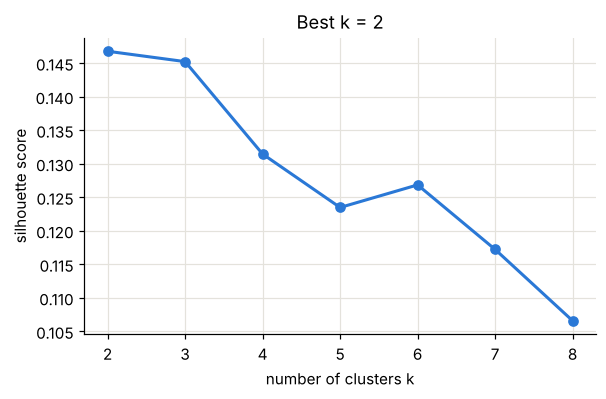

In [18]:
ks = range(2, 9)
scores = []
for k in ks:
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)
    scores.append(silhouette_score(Z, labels))

best_k = ks[int(np.argmax(scores))]
plt.figure(figsize=(6, 3.5))
plt.plot(ks, scores, marker="o", lw=2, color=BLUE)
plt.xlabel("number of clusters k")
plt.ylabel("silhouette score")
plt.title(f"Best k = {best_k}")
plt.show()

Silhouette score for k = 2: 0.147


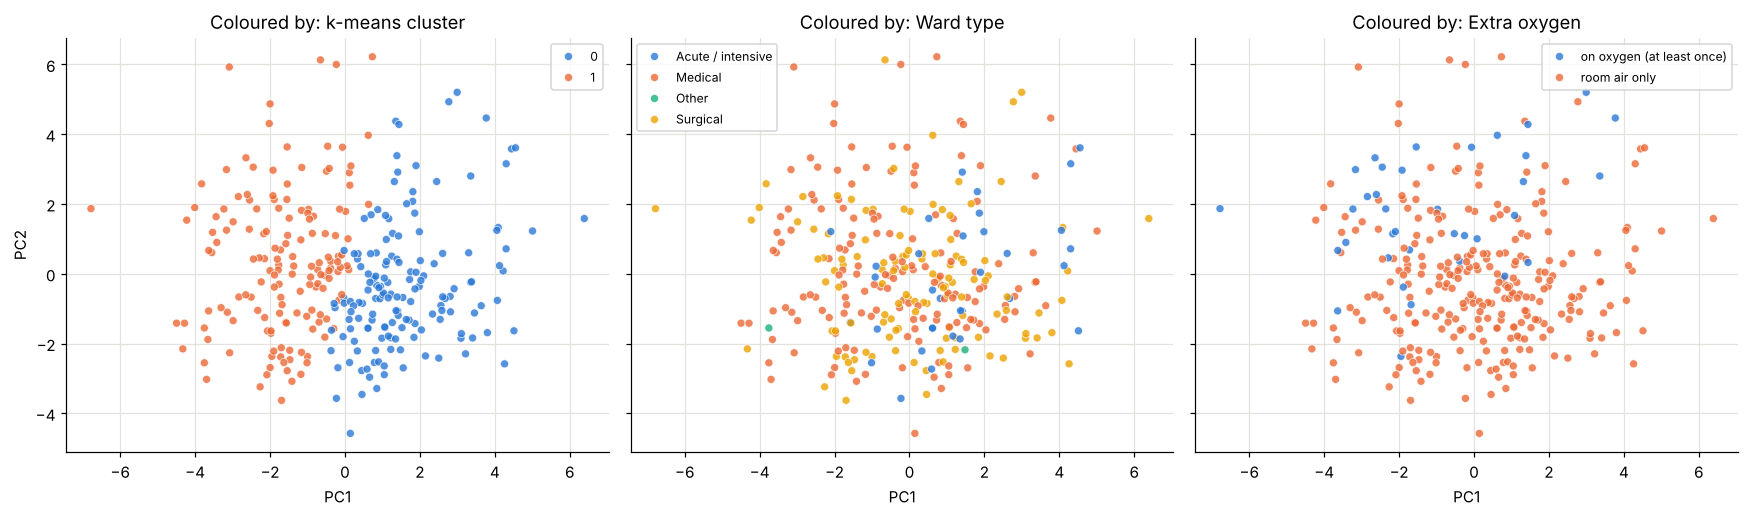

In [19]:
K = best_k                # ✏️ try other values, e.g. K = 3 or 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=0)
patients["cluster"] = kmeans.fit_predict(Z).astype(str)
print(f"Silhouette score for k = {K}: {silhouette_score(Z, patients['cluster']):.3f}")

# Plot the same PCA map three times, coloured by different things
patients["oxygen"] = np.where(patients["share_on_oxygen"] > 0, "on oxygen (at least once)", "room air only")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for ax, col, title in zip(axes, ["cluster", "ward_type", "oxygen"],
                          ["k-means cluster", "Ward type", "Extra oxygen"]):
    sns.scatterplot(data=patients, x="PC1", y="PC2", hue=col, hue_order=sorted(patients[col].unique()),
                    palette=PALETTE[:patients[col].nunique()], s=28, alpha=0.8,
                    edgecolor="white", linewidth=0.5, ax=ax)
    ax.set_title(f"Coloured by: {title}")
    ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

Step 5: **what do the clusters mean?** Look at the average patient in each cluster, in the original units:

In [20]:
profile = patients.groupby("cluster")[
    ["Systolic_mean", "O2_mean", "O2_min", "Pulse_mean", "Temp_max", "Rf_mean", "Rf_max",
     "max_NEWS", "share_on_oxygen", "n_measurements"]].mean().round(1)
profile.insert(0, "patients", patients["cluster"].value_counts().sort_index())
profile

,patients,Systolic_mean,O2_mean,O2_min,Pulse_mean,Temp_max,Rf_mean,Rf_max,max_NEWS,share_on_oxygen,n_measurements
cluster,,,,,,,,,,,
0,154,144.8,95.9,95.0,76.5,36.8,17.3,18.7,1.6,0.0,2.9
1,152,117.4,95.2,93.5,80.9,37.0,18.4,20.2,3.4,0.1,3.7


In [21]:
# How do the clusters line up with things we already knew? (counts of patients)
print(pd.crosstab(patients["cluster"], patients["oxygen"]), "\n")
print(pd.crosstab(patients["cluster"], patients["ward_type"]))

oxygen   on oxygen (at least once)  room air only
cluster                                          
0                                9            145
1                               27            125 

ward_type  Acute / intensive  Medical  Other  Surgical
cluster                                               
0                         27       64      1        62
1                          6       90      1        55


**Questions to discuss**
* Give each cluster a short "clinical" name based on its profile (e.g. *"stable"*, *"respiratory problems"*).
  Would a doctor agree?
* Do the clusters mostly just separate **oxygen vs. no oxygen**, or **one ward type from another**? In the lecture
  (slide 24) the impressive-looking clusters turned out to mostly separate **gender**. A cluster is only
  interesting if it tells us something we didn't already know.
* The silhouette score in the lecture was 0.35. Is your score higher or lower? Is a high score enough to say the
  clusters are medically meaningful?
* We threw away **time** completely. What information about a patient's course is lost?
  (This is why the lecture moved on to DTW, Gaussian processes and transformers.)

**✏️ Try it**
1. Set `MIN_MEASUREMENTS = 3` and re-run Part 4. What changes?
2. Remove `on_oxygen`-related effects by excluding the `O2_*` features from `FEATURE_COLS`. Do the clusters change?
3. Replace PCA with t-SNE (the cell below). Do the clusters look more separated? Remember that t-SNE distorts
   distances, so "nice-looking islands" can be misleading.

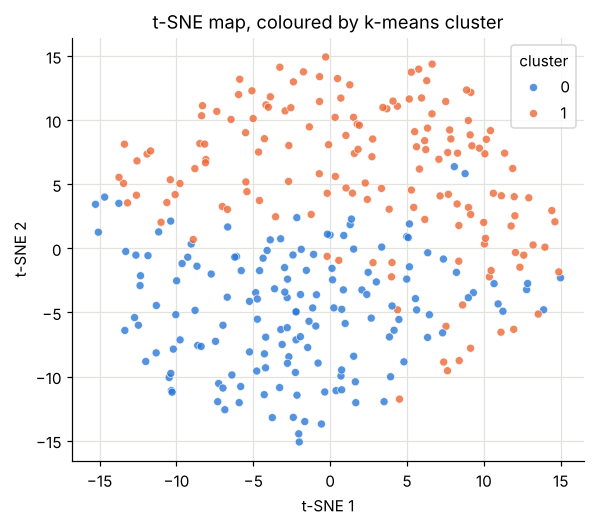

In [22]:
from sklearn.manifold import TSNE

T = TSNE(n_components=2, perplexity=min(30, len(Z) // 4), random_state=0).fit_transform(Z)
plt.figure(figsize=(6, 5))
sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=patients["cluster"], hue_order=sorted(patients["cluster"].unique()),
                palette=PALETTE[:K], s=28, alpha=0.8, edgecolor="white", linewidth=0.5)
plt.title("t-SNE map, coloured by k-means cluster")
plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2")
plt.show()

---
## Going further (optional)

* **Rebuild NEWS yourself.** Write a Python function `news(row)` that computes the score from the table at the top,
  apply it with `df.apply(news, axis=1)`, and check that it matches `EwsScore` for every row.
  Remember the oxygen (+2), consciousness (+3) and that `EwsType == 2` uses a different SpO₂ scale.
  Which vital sign adds points most often?
* **Plot patient courses.** For patients with many registrations, plot NEWS score against *hours since first
  registration* (`df.groupby("PatientID")["time"].transform("min")`). How regular is the time between
  measurements? Why does this make time-series methods harder?
* **Personal anomalies.** For each patient, compare each registration with that patient's own average (a
  z-score). Does a patient-specific alarm flag different registrations than the fixed NEWS thresholds?